# Gemini (RQ3)


## RQ3 STEP 1

In [1]:
!pip install -U google-genai python-dotenv

In [1]:
from google import genai
import getpass

print("Google GenAI imported successfully!")

Google GenAI imported successfully!


In [2]:
api_key = getpass.getpass("Enter your Gemini API Key: ")

client = genai.Client(api_key=api_key)

print("Gemini client created successfully!")

Enter your Gemini API Key:  ········


Gemini client created successfully!


## STEP 2 
Answer Generation

In [3]:
TOP_K_CHUNKS = 10
GEMINI_MODEL = "gemini-3.5-flash-lite"
GENERATION_CONFIG = {
    "temperature": 0.0,
}

MAX_RETRIES = 3
RETRY_BACKOFF_SECONDS = 5
SLEEP_BETWEEN_CALLS = 1

PROMPT_TEMPLATE = """أنت مساعد أكاديمي يجيب عن أسئلة الطلاب في جامعة ميداوشن.

أجب عن السؤال اعتمادًا فقط على المعلومات الموجودة في السياق المرفق.
لا تضف معلومات من خارج السياق.
إذا لم تكن المعلومات الكافية للإجابة موجودة في السياق، قل:
"لا توجد معلومات كافية في السياق للإجابة عن هذا السؤال."

اكتب إجابة واضحة ومباشرة باللغة العربية.

السؤال:
{question}

السياق:
{context}

الإجابة:
"""

print("تم تحميل الإعدادات المشتركة.")
print(f"- النموذج: {GEMINI_MODEL}")
print(f"- Top-K Chunks: {TOP_K_CHUNKS}")
print(f"- Generation config: {GENERATION_CONFIG}")

تم تحميل الإعدادات المشتركة.
- النموذج: gemini-3.5-flash-lite
- Top-K Chunks: 10
- Generation config: {'temperature': 0.0}


In [4]:
if "client" not in globals() or client is None:
    raise RuntimeError(
        "متغير client غير موجود. شغّل خلية إنشاء client أولاً."
    )

from google.genai import errors as genai_errors

print("client موجود. جاهز للمتابعة.")

client موجود. جاهز للمتابعة.


## STEP 3
uploade result 

In [5]:
import json, os

def _load_retrieval_file(path, var_name):
    if var_name in globals() and globals()[var_name]:
        existing = globals()[var_name]
        print(f"{var_name} موجود مسبقًا ({len(existing)} سؤال) - لن يُعاد تحميله.")
        return existing
    if not os.path.exists(path):
        raise FileNotFoundError(f"لم يتم العثور على الملف '{path}'.")
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    print(f"تم تحميل {var_name} من '{path}': {len(data)} سؤال.")
    return data

hybrid_results = _load_retrieval_file("hybrid_results.json", "hybrid_results")
reranked_all   = _load_retrieval_file("reranked_all.json", "reranked_all")

تم تحميل hybrid_results من 'hybrid_results.json': 50 سؤال.
تم تحميل reranked_all من 'reranked_all.json': 50 سؤال.


In [6]:
errors_found = []

if len(hybrid_results) != len(reranked_all):
    errors_found.append(
        f"عدد الأسئلة غير متطابق: hybrid_results={len(hybrid_results)} vs reranked_all={len(reranked_all)}"
    )

mismatched_order, mismatched_text, insufficient_chunks = [], [], []

for idx, (h_item, r_item) in enumerate(zip(hybrid_results, reranked_all)):
    h_qid, r_qid = h_item.get("query_id"), r_item.get("query_id")
    if h_qid != r_qid:
        mismatched_order.append((idx, h_qid, r_qid))
    if h_item.get("query") != r_item.get("query"):
        mismatched_text.append((h_qid, r_qid))
    h_n, r_n = len(h_item.get("results", [])), len(r_item.get("results", []))
    if h_n < TOP_K_CHUNKS or r_n < TOP_K_CHUNKS:
        insufficient_chunks.append((h_qid, h_n, r_n))

if mismatched_order:
    errors_found.append(f"ترتيب/تطابق query_id غير متطابق في {len(mismatched_order)} موضع: {mismatched_order[:5]}")
if mismatched_text:
    errors_found.append(f"نص السؤال غير متطابق في {len(mismatched_text)} حالة: {mismatched_text[:5]}")

if errors_found:
    raise AssertionError("فشل فحص العدالة:\n" + "\n".join(f"- {e}" for e in errors_found))

print("فحص العدالة ناجح - عدد الأسئلة:", len(hybrid_results))

if insufficient_chunks:
    print(f"\nتحذير: {len(insufficient_chunks)} سؤال لديه أقل من {TOP_K_CHUNKS} Chunks في أحد النظامين:")
    for qid, h_n, r_n in insufficient_chunks:
        print(f"   - {qid}: hybrid={h_n}, reranked={r_n}")
else:
    print(f"جميع الأسئلة تحتوي على {TOP_K_CHUNKS} Chunks على الأقل.")

فحص العدالة ناجح - عدد الأسئلة: 50
جميع الأسئلة تحتوي على 10 Chunks على الأقل.


## STEP 4
Unified RAG Answer Generation Function

In [7]:
import time

def generate_rag_answer(question, results, top_k=TOP_K_CHUNKS):
    """دالة موحّدة تُستخدم لكل من Non-reranked و Reranked بلا أي اختلاف."""
    top_results = results[:top_k]
    used_chunk_ids = [r["chunk_id"] for r in top_results]

    context = "\n\n".join(
        f"Chunk ID: {r['chunk_id']}\n{r['text']}"
        for r in top_results
    )

    prompt = PROMPT_TEMPLATE.format(question=question, context=context)

    last_error = None
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            interaction = client.interactions.create(
                model=GEMINI_MODEL,
                input=prompt,
                generation_config=GENERATION_CONFIG,
            )

            answer = interaction.output_text
            if not answer or not answer.strip():
                raise ValueError("استجابة Gemini فارغة (output_text خالٍ).")

            return answer.strip(), used_chunk_ids

        except genai_errors.ClientError as e:
            last_error = f"ClientError {e.code}: {e.message}"
            if e.code == 429 and attempt < MAX_RETRIES:
                time.sleep(RETRY_BACKOFF_SECONDS * attempt)
                continue
            raise RuntimeError(last_error) from e

        except genai_errors.ServerError as e:
            last_error = f"ServerError {e.code}: {e.message}"
            if attempt < MAX_RETRIES:
                time.sleep(RETRY_BACKOFF_SECONDS * attempt)
                continue
            raise RuntimeError(last_error) from e

        except genai_errors.APIError as e:
            last_error = f"APIError: {e}"
            raise RuntimeError(last_error) from e

        except ValueError as e:
            last_error = str(e)
            if attempt < MAX_RETRIES:
                time.sleep(RETRY_BACKOFF_SECONDS * attempt)
                continue
            raise

    raise RuntimeError(last_error or "فشل غير معروف.")

print("generate_rag_answer() جاهزة.")

generate_rag_answer() جاهزة.


In [8]:
#Code 1 — Generate Non-reranked Answers from hybrid_results
generation_results_nonreranked = []
stats_nonreranked = {"success": 0, "error": 0}

print(f"بدء توليد Non-reranked ({len(hybrid_results)} سؤال)...")

for i, item in enumerate(hybrid_results):
    query_id, question, results = item["query_id"], item["query"], item["results"]

    record = {
        "query_id": query_id,
        "query": question,
        "retrieved_chunk_ids": [r["chunk_id"] for r in results[:TOP_K_CHUNKS]],
        "answer": None,
        "error": None,
    }

    try:
        answer, used_ids = generate_rag_answer(question, results)
        record["answer"] = answer
        record["retrieved_chunk_ids"] = used_ids
        stats_nonreranked["success"] += 1
        status = "OK"
    except Exception as e:
        error_message = f"{type(e).__name__}: {e}"
        record["answer"] = f"ERROR: {error_message}"
        record["error"] = error_message
        stats_nonreranked["error"] += 1
        status = f"FAILED ({error_message})"

    generation_results_nonreranked.append(record)
    print(f"[Non-reranked] {i+1}/{len(hybrid_results)} - {query_id}: {status}")
    time.sleep(SLEEP_BETWEEN_CALLS)

print("\nانتهى Non-reranked. نجاح:", stats_nonreranked["success"], "فشل:", stats_nonreranked["error"])

بدء توليد Non-reranked (50 سؤال)...
[Non-reranked] 1/50 - Q01: OK
[Non-reranked] 2/50 - Q02: OK
[Non-reranked] 3/50 - Q03: OK
[Non-reranked] 4/50 - Q04: OK
[Non-reranked] 5/50 - Q05: OK
[Non-reranked] 6/50 - Q06: OK
[Non-reranked] 7/50 - Q07: OK
[Non-reranked] 8/50 - Q08: OK
[Non-reranked] 9/50 - Q09: OK
[Non-reranked] 10/50 - Q10: OK
[Non-reranked] 11/50 - Q11: OK
[Non-reranked] 12/50 - Q12: OK
[Non-reranked] 13/50 - Q13: OK
[Non-reranked] 14/50 - Q14: OK
[Non-reranked] 15/50 - Q15: OK
[Non-reranked] 16/50 - Q16: OK
[Non-reranked] 17/50 - Q17: OK
[Non-reranked] 18/50 - Q18: OK
[Non-reranked] 19/50 - Q19: OK
[Non-reranked] 20/50 - Q20: OK
[Non-reranked] 21/50 - Q21: OK
[Non-reranked] 22/50 - Q22: OK
[Non-reranked] 23/50 - Q23: OK
[Non-reranked] 24/50 - Q24: OK
[Non-reranked] 25/50 - Q25: OK
[Non-reranked] 26/50 - Q26: OK
[Non-reranked] 27/50 - Q27: OK
[Non-reranked] 28/50 - Q28: OK
[Non-reranked] 29/50 - Q29: OK
[Non-reranked] 30/50 - Q30: OK
[Non-reranked] 31/50 - Q31: OK
[Non-reranke

In [9]:
with open("generation_results_nonreranked.json", "w", encoding="utf-8") as f:
    json.dump(generation_results_nonreranked, f, ensure_ascii=False, indent=2)

print("تم حفظ generation_results_nonreranked.json -", len(generation_results_nonreranked), "سجل")

تم حفظ generation_results_nonreranked.json - 50 سجل


In [10]:
#Code 2 — Generate reranked Answers from reranked_all
generation_results_reranked = []
stats_reranked = {"success": 0, "error": 0}

print(f"بدء توليد Reranked ({len(reranked_all)} سؤال)...")

for i, item in enumerate(reranked_all):
    query_id, question, results = item["query_id"], item["query"], item["results"]

    record = {
        "query_id": query_id,
        "query": question,
        "retrieved_chunk_ids": [r["chunk_id"] for r in results[:TOP_K_CHUNKS]],
        "answer": None,
        "error": None,
    }

    try:
        answer, used_ids = generate_rag_answer(question, results)
        record["answer"] = answer
        record["retrieved_chunk_ids"] = used_ids
        stats_reranked["success"] += 1
        status = "OK"
    except Exception as e:
        error_message = f"{type(e).__name__}: {e}"
        record["answer"] = f"ERROR: {error_message}"
        record["error"] = error_message
        stats_reranked["error"] += 1
        status = f"FAILED ({error_message})"

    generation_results_reranked.append(record)
    print(f"[Reranked] {i+1}/{len(reranked_all)} - {query_id}: {status}")
    time.sleep(SLEEP_BETWEEN_CALLS)

print("\nانتهى Reranked. نجاح:", stats_reranked["success"], "فشل:", stats_reranked["error"])

بدء توليد Reranked (50 سؤال)...
[Reranked] 1/50 - Q01: OK
[Reranked] 2/50 - Q02: OK
[Reranked] 3/50 - Q03: OK
[Reranked] 4/50 - Q04: OK
[Reranked] 5/50 - Q05: OK
[Reranked] 6/50 - Q06: OK
[Reranked] 7/50 - Q07: OK
[Reranked] 8/50 - Q08: OK
[Reranked] 9/50 - Q09: OK
[Reranked] 10/50 - Q10: OK
[Reranked] 11/50 - Q11: OK
[Reranked] 12/50 - Q12: OK
[Reranked] 13/50 - Q13: OK
[Reranked] 14/50 - Q14: OK
[Reranked] 15/50 - Q15: OK
[Reranked] 16/50 - Q16: OK
[Reranked] 17/50 - Q17: OK
[Reranked] 18/50 - Q18: OK
[Reranked] 19/50 - Q19: OK
[Reranked] 20/50 - Q20: OK
[Reranked] 21/50 - Q21: OK
[Reranked] 22/50 - Q22: OK
[Reranked] 23/50 - Q23: OK
[Reranked] 24/50 - Q24: OK
[Reranked] 25/50 - Q25: OK
[Reranked] 26/50 - Q26: OK
[Reranked] 27/50 - Q27: OK
[Reranked] 28/50 - Q28: OK
[Reranked] 29/50 - Q29: OK
[Reranked] 30/50 - Q30: OK
[Reranked] 31/50 - Q31: OK
[Reranked] 32/50 - Q32: OK
[Reranked] 33/50 - Q33: OK
[Reranked] 34/50 - Q34: OK
[Reranked] 35/50 - Q35: OK
[Reranked] 36/50 - Q36: OK
[Rera

In [11]:
with open("generation_results_reranked.json", "w", encoding="utf-8") as f:
    json.dump(generation_results_reranked, f, ensure_ascii=False, indent=2)

print("تم حفظ generation_results_reranked.json -", len(generation_results_reranked), "سجل")

تم حفظ generation_results_reranked.json - 50 سجل


In [13]:
##checking files

with open("generation_results_nonreranked.json", "r", encoding="utf-8") as f:
    check_nonreranked = json.load(f)
with open("generation_results_reranked.json", "r", encoding="utf-8") as f:
    check_reranked = json.load(f)

print("عدد الأسئلة - Non-reranked:", len(check_nonreranked))
print("عدد الأسئلة - Reranked:    ", len(check_reranked))
assert len(check_nonreranked) == len(check_reranked), "عدد الأسئلة غير متطابق!"

ids_nonreranked = [r["query_id"] for r in check_nonreranked]
ids_reranked = [r["query_id"] for r in check_reranked]

if ids_nonreranked == ids_reranked:
    print("معرّفات الأسئلة متطابقة ومرتبة بنفس الترتيب.")
else:
    mism = [(i, a, b) for i, (a, b) in enumerate(zip(ids_nonreranked, ids_reranked)) if a != b]
    print(f"هناك {len(mism)} اختلاف:", mism[:10])

chunk_count_issues = [
    (r["query_id"], len(r.get("retrieved_chunk_ids", [])))
    for r in check_nonreranked + check_reranked
    if len(r.get("retrieved_chunk_ids", [])) != TOP_K_CHUNKS
]
if chunk_count_issues:
    print(f"{len(chunk_count_issues)} سجل لا يحتوي {TOP_K_CHUNKS} chunk ids:", chunk_count_issues[:10])
else:
    print(f"جميع السجلات تحتوي {TOP_K_CHUNKS} chunk ids بالضبط.")

def count_success_error(records):
    errors = sum(1 for r in records if str(r.get("answer", "")).startswith("ERROR:") or r.get("error"))
    return len(records) - errors, errors

s_nr, e_nr = count_success_error(check_nonreranked)
s_r, e_r = count_success_error(check_reranked)
print(f"\nNon-reranked -> ناجحة: {s_nr}, فاشلة: {e_nr}")
print(f"Reranked     -> ناجحة: {s_r}, فاشلة: {e_r}")

عدد الأسئلة - Non-reranked: 50
عدد الأسئلة - Reranked:     50
معرّفات الأسئلة متطابقة ومرتبة بنفس الترتيب.
جميع السجلات تحتوي 10 chunk ids بالضبط.

Non-reranked -> ناجحة: 50, فاشلة: 0
Reranked     -> ناجحة: 50, فاشلة: 0


---

# RQ3 — Does reranking improve generated-answer quality compared with the initial (non-reranked) retrieval output?

RQ1/RQ2 already showed that **Hybrid + Reranking** gives the best *retrieval* metrics
(Recall@5/10, MRR, NDCG@10). RQ3 asks a different question: once the retrieved chunks
are handed to the LLM to actually *write an answer*, does reranking still help, or does
it only move numbers around in the retrieval metrics without changing what the student
actually reads?

**Method — human evaluation**

Answer quality is assessed through **human evaluation by Arabic-speaking evaluators**,
who judge each generated answer on three criteria relative to the retrieved source
documents it was generated from:

- **Relevance** — does the answer actually address the question asked?
- **Correctness** — is the information in the answer accurate, compared with the
  retrieved source documents?
- **Faithfulness** — is every claim in the answer actually supported by the retrieved
  source documents (no information invented beyond them)?

To keep the comparison fair, both answer sets above were generated with the *exact
same* prompt and model — the only difference is which retrieved chunks were used: the
**non-reranked** Hybrid top-10 (`generation_results_nonreranked.json`) vs. the
**reranked** top-10 (`generation_results_reranked.json`).
Evaluators rate answers **blind**: for every query, the two answers are shown as
anonymous "System A" / "System B", with the assignment randomized per query, so
evaluators never know which one came from reranking. If more than one evaluator rates
the same sheet, inter-rater agreement is checked (Cohen's Kappa) before combining
their scores. Because the same 50 queries produce both a reranked-answer score and a
non-reranked-answer score, the two conditions are compared with a **paired** Wilcoxon
signed-rank test and bootstrap test, plus a win/tie/loss count per query.

## Step 5 
Load both generated answer sets and supporting data

In [14]:
import json

with open("generation_results_reranked.json", "r", encoding="utf-8") as f:
    generation_results_reranked = json.load(f)

with open("generation_results_nonreranked.json", "r", encoding="utf-8") as f:
    generation_results_nonreranked = json.load(f)

with open("midocean_chunks_final.json", "r", encoding="utf-8") as f:
    all_chunks = json.load(f)

chunk_lookup = {c["chunk_id"]: c for c in all_chunks}

with open("evaluation_queries_final.json", "r", encoding="utf-8") as f:
    evaluation_queries_final = json.load(f)

reranked_by_id = {item["query_id"]: item for item in generation_results_reranked}
nonreranked_by_id = {item["query_id"]: item for item in generation_results_nonreranked}

print("Reranked answers:", len(generation_results_reranked))
print("Non-reranked answers:", len(generation_results_nonreranked))
print("Chunks loaded:", len(chunk_lookup))
print("Evaluation queries:", len(evaluation_queries_final))

Reranked answers: 50
Non-reranked answers: 50
Chunks loaded: 101
Evaluation queries: 50


## Step 6 
Build the blind human-evaluation sheet

For every query we create **two rows**, one per condition, labeled only `System A` / `System B`. Which condition (reranked / non-reranked) is "A" and which is "B" is **randomized independently for every query**, so evaluators cannot learn a pattern and cannot tell which system produced which answer. The real mapping is written to a separate key file that must **not** be shown to the evaluators.

In [15]:
!pip install -U openpyxl scikit-learn

In [16]:
import random
import pandas as pd

random.seed(42)  # reproducible blinding / order assignment

blind_rows = []
key_rows = []

for q in evaluation_queries_final:
    qid = q["query_id"]
    question = q["query"]

    conditions = [
        ("reranked", reranked_by_id[qid]),
        ("nonreranked", nonreranked_by_id[qid])
    ]
    random.shuffle(conditions)  # randomize which is System A / System B per query

    for label, (condition, item) in zip(["System A", "System B"], conditions):

        retrieved_ids = item.get("retrieved_chunk_ids", [])
        source_text = "\n\n".join(
            f"[{cid}] {chunk_lookup[cid]['text']}"
            for cid in retrieved_ids
            if cid in chunk_lookup
        )

        blind_rows.append({
            "query_id": qid,
            "question": question,
            "system_label": label,
            "retrieved_sources": source_text,
            "generated_answer": item["answer"],
            "relevance_1_5": "",
            "correctness_1_5": "",
            "faithfulness_1_5": "",
            "comments": ""
        })

        key_rows.append({
            "query_id": qid,
            "system_label": label,
            "actual_condition": condition
        })

human_eval_sheet = pd.DataFrame(blind_rows)
blind_key = pd.DataFrame(key_rows)

print("Evaluation sheet rows:", len(human_eval_sheet),
      "(", len(evaluation_queries_final), "queries x 2 conditions )")
human_eval_sheet.head()

Evaluation sheet rows: 100 ( 50 queries x 2 conditions )


,query_id,question,system_label,retrieved_sources,generated_answer,relevance_1_5,correctness_1_5,faithfulness_1_5,comments
0,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System A,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,برامج الماجستير المتاحة في الجامعة هي:\n1. ماج...,,,,
1,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System B,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,بناءً على السياق المرفق، فإن برامج الماجستير ا...,,,,
2,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System A,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,,,,
3,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System B,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,,,,
4,Q03,هل توجد برامج دكتوراه في الجامعة؟,System A,[DOC_001_CHUNK_0006] برامج الدكتوراه التي تقدم...,نعم، تقدم الجامعة العديد من برامج الدكتوراه، و...,,,,


In [17]:
# Arabic instructions shown to evaluators on a separate sheet of the workbook
instructions_text = [
    ["تعليمات التقييم البشري لجودة الإجابات (RQ3)"],
    [""],
    ["سيقوم كل مُقيِّم بقراءة السؤال، والمصادر المسترجعة (الوثائق التي استُخدمت لتوليد الإجابة)،"],
    ["والإجابة المولّدة، ثم يمنح كل إجابة تقييمًا من 1 إلى 5 على ثلاثة معايير:"],
    [""],
    ["1) الملاءمة / الصلة بالسؤال (Relevance): هل تجيب الإجابة فعليًّا على السؤال المطروح؟"],
    ["   5 = تجيب بشكل مباشر وكامل عن السؤال، 1 = لا علاقة لها بالسؤال."],
    [""],
    ["2) الصحة (Correctness): هل المعلومات الواردة في الإجابة صحيحة مقارنة بالمصادر المسترجعة؟"],
    ["   5 = المعلومات صحيحة تمامًا، 1 = المعلومات خاطئة تمامًا."],
    [""],
    ["3) الالتزام بالمصدر (Faithfulness): هل كل معلومة في الإجابة مذكورة فعليًّا في المصادر"],
    ["   المسترجعة المرفقة، دون إضافة معلومات من خارجها (Hallucination)؟"],
    ["   5 = كل المعلومات مدعومة بالمصدر، 1 = تحتوي على معلومات لا توجد في المصدر."],
    [""],
    ["ملاحظات مهمة:"],
    ["- كل سؤال يظهر مرتين، بإجابتين مسمّيتين 'System A' و 'System B' فقط — هذه التسمية"],
    ["  عشوائية ولا تدل على أي نظام استرجاع بعينه، والهدف منها إخفاء هوية النظام عن المُقيِّم"],
    ["  (Blind Evaluation) لتجنّب التحيز."],
    ["- يُرجى تقييم كل إجابة بالاعتماد فقط على 'المصادر المسترجعة' المرفقة معها، لا على معرفتك"],
    ["  الشخصية بموضوع السؤال."],
    ["- عمود 'comments' اختياري ويمكن استخدامه لتوضيح سبب التقييم أو ملاحظة أي خطأ واضح."],
]

with pd.ExcelWriter("RQ3_human_evaluation_sheet.xlsx", engine="openpyxl") as writer:
    pd.DataFrame(instructions_text).to_excel(
        writer, sheet_name="Instructions", index=False, header=False
    )
    human_eval_sheet.to_excel(writer, sheet_name="Evaluation", index=False)

# The mapping between System A/B and the actual condition (reranked /
# non-reranked) is kept SEPARATE and must NOT be shared with evaluators,
# otherwise the blind evaluation is broken.
blind_key.to_csv("RQ3_blind_key_DO_NOT_SHARE.csv", index=False, encoding="utf-8-sig")

print("Saved RQ3_human_evaluation_sheet.xlsx  -> give this file to evaluators")
print("Saved RQ3_blind_key_DO_NOT_SHARE.csv   -> keep this for analysis only, do NOT share")

Saved RQ3_human_evaluation_sheet.xlsx  -> give this file to evaluators
Saved RQ3_blind_key_DO_NOT_SHARE.csv   -> keep this for analysis only, do NOT share


If more than one evaluator will rate the sheet, make one identical copy per evaluator (do **not** regenerate the sheet separately for each evaluator — that would reshuffle the blinding and the two evaluators would no longer be rating the same System A/B assignment).

In [18]:
import shutil

evaluator_names = ["evaluator1", "evaluator2"]  # update with your actual evaluators' names

for name in evaluator_names:
    shutil.copy(
        "RQ3_human_evaluation_sheet.xlsx",
        f"RQ3_human_evaluation_sheet_{name}.xlsx"
    )

print("Created one evaluation copy per evaluator:", evaluator_names)
print("Send each evaluator only their own file. Do not send RQ3_blind_key_DO_NOT_SHARE.csv.")

Created one evaluation copy per evaluator: ['evaluator1', 'evaluator2']
Send each evaluator only their own file. Do not send RQ3_blind_key_DO_NOT_SHARE.csv.


In [23]:
#Load the completed human ratings

import pandas as pd

# Update this dict with the filenames you actually received back from each
# Arabic-speaking evaluator.
evaluator_files = {
    "evaluator1": "RQ3_human_evaluation_sheet_evaluator1.xlsx",
    "evaluator2": "RQ3_human_evaluation_sheet_evaluator2.xlsx",
}

blind_key = pd.read_csv("RQ3_blind_key_DO_NOT_SHARE.csv")

all_ratings = []

for evaluator, path in evaluator_files.items():
    df = pd.read_excel(path, sheet_name="Evaluation")
    df["evaluator"] = evaluator

    # Restore the true condition (reranked / nonreranked) for analysis only -
    # evaluators never saw this mapping.
    df = df.merge(blind_key, on=["query_id", "system_label"], how="left")

    all_ratings.append(df)

human_ratings = pd.concat(all_ratings, ignore_index=True)

for col in ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]:
    human_ratings[col] = pd.to_numeric(human_ratings[col], errors="coerce")

print("Loaded human ratings:", len(human_ratings), "rows from", len(evaluator_files), "evaluator(s)")

missing = human_ratings[["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]].isna().any(axis=1).sum()
if missing:
    print(f"Warning: {missing} rows have missing/non-numeric scores - check with evaluators before analysis.")

human_ratings.head()

Loaded human ratings: 200 rows from 2 evaluator(s)


,query_id,question,system_label,retrieved_sources,generated_answer,relevance_1_5,correctness_1_5,faithfulness_1_5,comments,evaluator,actual_condition
0,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System A,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,برامج الماجستير المتاحة في الجامعة هي:\n1. ماج...,4,4,5,NaN,evaluator1,nonreranked
1,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System B,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,بناءً على السياق المرفق، فإن برامج الماجستير ا...,5,5,5,NaN,evaluator1,reranked
2,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System A,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,5,5,5,NaN,evaluator1,nonreranked
3,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System B,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,4,5,5,NaN,evaluator1,reranked
4,Q03,هل توجد برامج دكتوراه في الجامعة؟,System A,[DOC_001_CHUNK_0006] برامج الدكتوراه التي تقدم...,نعم، تقدم الجامعة العديد من برامج الدكتوراه، و...,5,5,5,NaN,evaluator1,reranked


## Step 7 
Inter-rater reliability 

In [24]:
from sklearn.metrics import cohen_kappa_score

evaluators = human_ratings["evaluator"].unique().tolist()

if len(evaluators) >= 2:
    e1, e2 = evaluators[0], evaluators[1]

    pivot = human_ratings.pivot_table(
        index=["query_id", "system_label"],
        columns="evaluator",
        values=["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]
    )

    print(f"Inter-rater agreement (linear-weighted Cohen's Kappa): {e1} vs {e2}")
    print("-" * 60)

    for metric in ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]:
        paired = pivot[metric][[e1, e2]].dropna()
        kappa = cohen_kappa_score(
            paired[e1].round(), paired[e2].round(), weights="linear"
        )
        print(f"{metric:<20}: kappa = {kappa:.3f}  (n={len(paired)})")

    print("\nRule of thumb: >0.80 almost perfect, 0.60-0.80 substantial, "
          "0.40-0.60 moderate, <0.40 weak agreement.")
else:
    print("Only one evaluator found - inter-rater reliability cannot be computed.")
    print("Proceeding with this evaluator's scores directly for the RQ3 comparison.")

Inter-rater agreement (linear-weighted Cohen's Kappa): evaluator1 vs evaluator2
------------------------------------------------------------
relevance_1_5       : kappa = 0.873  (n=100)
correctness_1_5     : kappa = 0.871  (n=100)
faithfulness_1_5    : kappa = 0.823  (n=100)

Rule of thumb: >0.80 almost perfect, 0.60-0.80 substantial, 0.40-0.60 moderate, <0.40 weak agreement.


**Aggregate scores per query and condition**

Average across evaluators (when there is more than one) to get a single Relevance / Correctness / Faithfulness score per query, per condition (reranked vs. non-reranked), using the de-blinded `actual_condition` column.

In [25]:
## Aggregate scores per query and condition

per_condition = (
    human_ratings
    .groupby(["query_id", "actual_condition"])[
        ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]
    ]
    .mean()
    .reset_index()
)

per_condition["overall_quality"] = per_condition[
    ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]
].mean(axis=1)

reranked_scores = per_condition[per_condition["actual_condition"] == "reranked"].drop(columns="actual_condition")
nonreranked_scores = per_condition[per_condition["actual_condition"] == "nonreranked"].drop(columns="actual_condition")

rq3_df = reranked_scores.merge(
    nonreranked_scores, on="query_id", suffixes=("_reranked", "_nonreranked")
).dropna()

metrics = ["relevance_1_5", "correctness_1_5", "faithfulness_1_5", "overall_quality"]

print("\nRQ3 - Human-judged Generated Answer Quality (1-5 scale, averaged across evaluators)")
print("=" * 70)
print(f"{'Metric':<18}{'Non-reranked':>15}{'Reranked':>15}")
for m in metrics:
    nr = rq3_df[f"{m}_nonreranked"].mean()
    rr = rq3_df[f"{m}_reranked"].mean()
    print(f"{m:<18}{nr:>15.3f}{rr:>15.3f}")

rq3_df.to_csv("RQ3_human_quality_scores_per_query.csv", index=False, encoding="utf-8-sig")
print("\nSaved per-query scores to RQ3_human_quality_scores_per_query.csv")


RQ3 - Human-judged Generated Answer Quality (1-5 scale, averaged across evaluators)
Metric               Non-reranked       Reranked
relevance_1_5               4.690          4.930
correctness_1_5             4.630          4.900
faithfulness_1_5            4.690          4.890
overall_quality             4.670          4.907

Saved per-query scores to RQ3_human_quality_scores_per_query.csv


**Paired significance test (reranked vs. non-reranked, same 50 queries)**

Scores are bounded 1-5 and come from the same 50 queries under two conditions, so a **paired** test is appropriate. The Wilcoxon signed-rank test is reported as the primary test (robust to the non-normal, ordinal nature of human ratings)

In [26]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

rng = np.random.default_rng(42)
n_bootstrap = 20000

rq3_summary = []

criteria = {
    "Relevance": ("relevance_1_5_nonreranked", "relevance_1_5_reranked"),
    "Correctness": ("correctness_1_5_nonreranked", "correctness_1_5_reranked"),
    "Faithfulness": ("faithfulness_1_5_nonreranked", "faithfulness_1_5_reranked"),
    "Overall Quality": ("overall_quality_nonreranked", "overall_quality_reranked")
}

for criterion, (col_A, col_B) in criteria.items():

    A = rq3_df[col_A].to_numpy(dtype=float)
    B = rq3_df[col_B].to_numpy(dtype=float)

    valid = np.isfinite(A) & np.isfinite(B)
    A = A[valid]
    B = B[valid]

    differences = B - A

    mean_A = np.mean(A)
    mean_B = np.mean(B)
    mean_diff = np.mean(differences)

    wins = int(np.sum(differences > 0))
    ties = int(np.sum(differences == 0))
    losses = int(np.sum(differences < 0))

    if np.any(differences != 0):
        wilcoxon_stat, wilcoxon_p = wilcoxon(B, A)
    else:
        wilcoxon_stat = np.nan
        wilcoxon_p = 1.0

    boot_means = np.empty(n_bootstrap)
    for i in range(n_bootstrap):
        sample = rng.choice(differences, size=len(differences), replace=True)
        boot_means[i] = np.mean(sample)

    lower, upper = np.percentile(boot_means, [2.5, 97.5])

    rq3_summary.append({
        "Criterion": criterion,
        "Mean Non-reranked": mean_A,
        "Mean Reranked": mean_B,
        "Mean Difference": mean_diff,
        "Wins": wins,
        "Ties": ties,
        "Losses": losses,
        "Wilcoxon Statistic": wilcoxon_stat,
        "Wilcoxon p-value": wilcoxon_p,
        "Bootstrap 95% CI Lower": lower,
        "Bootstrap 95% CI Upper": upper
    })

rq3_summary_df = pd.DataFrame(rq3_summary).round(4)
display(rq3_summary_df)

rq3_summary_df.to_csv("RQ3_final_results.csv", index=False, encoding="utf-8-sig")
print("Results saved successfully!")

,Criterion,Mean Non-reranked,Mean Reranked,Mean Difference,Wins,Ties,Losses,Wilcoxon Statistic,Wilcoxon p-value,Bootstrap 95% CI Lower,Bootstrap 95% CI Upper
0,Relevance,4.69,4.9300,0.2400,12,34,4,25.0,0.0177,0.05,0.4700
1,Correctness,4.63,4.9000,0.2700,12,33,5,31.5,0.0290,0.05,0.5300
2,Faithfulness,4.69,4.8900,0.2000,12,32,6,42.0,0.0511,0.01,0.4300
3,Overall Quality,4.67,4.9067,0.2367,18,24,8,85.5,0.0215,0.05,0.4567


Results saved successfully!


## STEP 8
Visualize the comparison

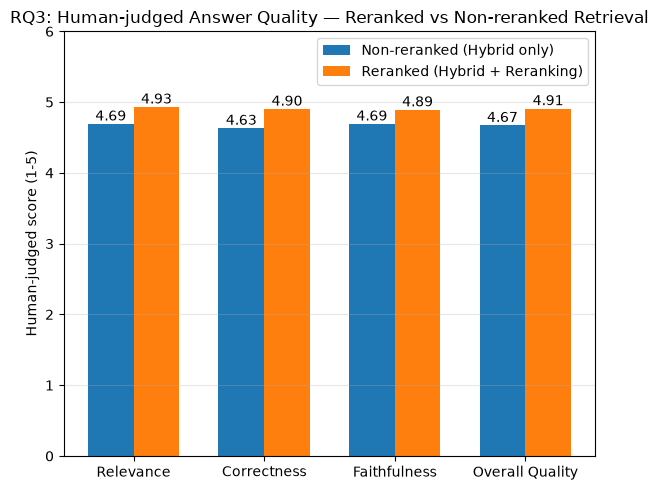

In [30]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["Relevance", "Correctness", "Faithfulness", "Overall Quality"]
nonreranked_means = [
    rq3_df["relevance_1_5_nonreranked"].mean(),
    rq3_df["correctness_1_5_nonreranked"].mean(),
    rq3_df["faithfulness_1_5_nonreranked"].mean(),
    rq3_df["overall_quality_nonreranked"].mean()
]
reranked_means = [
    rq3_df["relevance_1_5_reranked"].mean(),
    rq3_df["correctness_1_5_reranked"].mean(),
    rq3_df["faithfulness_1_5_reranked"].mean(),
    rq3_df["overall_quality_reranked"].mean()
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(6, 5))
plt.bar(x - width/2, nonreranked_means, width, label="Non-reranked (Hybrid only)")
plt.bar(x + width/2, reranked_means, width, label="Reranked (Hybrid + Reranking)")

plt.xticks(x, labels)
plt.ylabel("Human-judged score (1-5)")
plt.ylim(0, 6)
plt.title("RQ3: Human-judged Answer Quality — Reranked vs Non-reranked Retrieval")
plt.legend()
plt.grid(axis="y", alpha=0.3)

for i, (v1, v2) in enumerate(zip(nonreranked_means, reranked_means)):
    plt.text(i - width/2, v1 + 0.05, f"{v1:.2f}", ha="center")
    plt.text(i + width/2, v2 + 0.05, f"{v2:.2f}", ha="center")

plt.tight_layout()
plt.savefig("RQ3_quality_comparison.png", dpi=150)
plt.show()

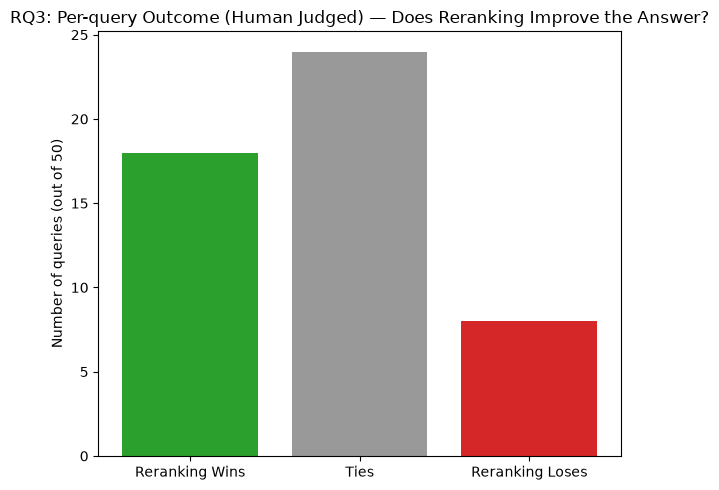

In [31]:
overall_row = next(r for r in rq3_summary if r["Criterion"] == "Overall Quality")

plt.figure(figsize=(6, 5))
plt.bar(
    ["Reranking Wins", "Ties", "Reranking Loses"],
    [overall_row["Wins"], overall_row["Ties"], overall_row["Losses"]],
    color=["#2ca02c", "#999999", "#d62728"]
)
plt.ylabel("Number of queries (out of 50)")
plt.title("RQ3: Per-query Outcome (Human Judged) — Does Reranking Improve the Answer?")
plt.tight_layout()
plt.savefig("RQ3_win_tie_loss.png", dpi=150)
plt.show()

## RQ3 Step 9 — Conclusion

Read the `RQ3_final_results.csv` table above: if the **mean Overall Quality is higher for the reranked condition** and the **Wilcoxon p-value < 0.05**, the human evaluators found reranking produces a statistically significant improvement in generated-answer quality, not just in retrieval metrics. If the means are close and p ≥ 0.05, the human evaluation does not support a significant generation-quality improvement from reranking for this dataset/query set — worth noting since RQ1/RQ2 already showed Hybrid alone has Recall@10 = 0.98, almost identical to Hybrid + Reranking (0.98), so the gold chunk is already present in context for both conditions most of the time; RQ3 isolates whether reranking's effect on *ordering* (better MRR/NDCG) still helps once that context reaches a human reader of the generated answer.